# Breast Cancer Prediction Project

## Problem Statement
Breast cancer is one of the most common diseases affecting women worldwide. Early detection can significantly improve treatment outcomes and survival rates. In this project, we build a machine learning model to predict whether a tumor is **benign (non-cancerous)** or **malignant (cancerous)** based on medical features such as radius, texture, perimeter, area, and smoothness.

## Objectives
- Perform data preprocessing and cleaning.
- Apply classification algorithms: **SVM**, **KNN**, and **Tree-based models (Random Forest)**.
- Evaluate model performance using metrics like Accuracy, Confusion Matrix, and Classification Report.
- Identify the most accurate model.


### Environment Fix (NumPy Version Control)
Run this cell only if you encounter NumPy compatibility errors. Otherwise, skip to Section 1.


In [3]:
# !pip install "numpy<2.0.0" "pandas<3.0.0" --force-reinstall
# import os
# os._exit(00) # This restarts the kernel automatically


## 1. Import Libraries
In this section, we import all necessary libraries for data handling, visualization, and machine learning.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set(style='whitegrid')


## 2. Dataset Description and Loading
The dataset contains 30 medical features extracted from digitized images of breast masses. Features include mean, standard error, and 'worst' values for properties like radius, texture, and area.


In [7]:
# Load the dataset
try:
    df = pd.read_csv('breast-cancer.csv')
    print('Dataset loaded successfully!')
    print(df.head())
except FileNotFoundError:
    print('Error: breast-cancer.csv not found in the directory.')


Dataset loaded successfully!
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_wor

## 3. Data Preprocessing
Preprocessing involves cleaning the data, encoding categorical variables, and scaling features for better model performance.


In [9]:
# 1. Remove the 'id' column as it doesn't contribute to prediction
if 'id' in df.columns:
    df = df.drop('id', axis=1)

# 2. Encode the target 'diagnosis' column (M = 1, B = 0)
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])

# 3. Separate features (X) and target (y)
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# 4. Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Feature Scaling - Crucial for SVM and KNN distance calculations
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Preprocessing complete. Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}')


Preprocessing complete. Training samples: 455, Test samples: 114


## 4. Model Implementation and Evaluation
We will now implement and evaluate the three models required: SVM, KNN, and a Tree-based model (Random Forest).


In [11]:
def evaluate_model(model, X_test_data, y_test_data, model_name):
    """Utility function to print evaluation metrics"""
    y_pred = model.predict(X_test_data)
    acc = accuracy_score(y_test_data, y_pred)
    print(f'--- {model_name} Evaluation ---')
    print(f'Accuracy Score: {acc:.4f}')
    print('\nConfusion Matrix:')
    print(confusion_matrix(y_test_data, y_pred))
    print('\nClassification Report:')
    print(classification_report(y_test_data, y_pred))
    return acc


### 4.1 Support Vector Machine (SVM)


In [13]:
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_acc = evaluate_model(svm_model, X_test_scaled, y_test, 'SVM')


--- SVM Evaluation ---
Accuracy Score: 0.9561

Confusion Matrix:
[[68  3]
 [ 2 41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96        71
           1       0.93      0.95      0.94        43

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



### 4.2 K-Nearest Neighbors (KNN)


In [15]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_acc = evaluate_model(knn_model, X_test_scaled, y_test, 'KNN')


--- KNN Evaluation ---
Accuracy Score: 0.9474

Confusion Matrix:
[[68  3]
 [ 3 40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



### 4.3 Tree-based Model (Random Forest)


In [17]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_acc = evaluate_model(rf_model, X_test, y_test, 'Random Forest')


--- Random Forest Evaluation ---
Accuracy Score: 0.9649

Confusion Matrix:
[[70  1]
 [ 3 40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        71
           1       0.98      0.93      0.95        43

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 5. Model Comparison and Conclusion


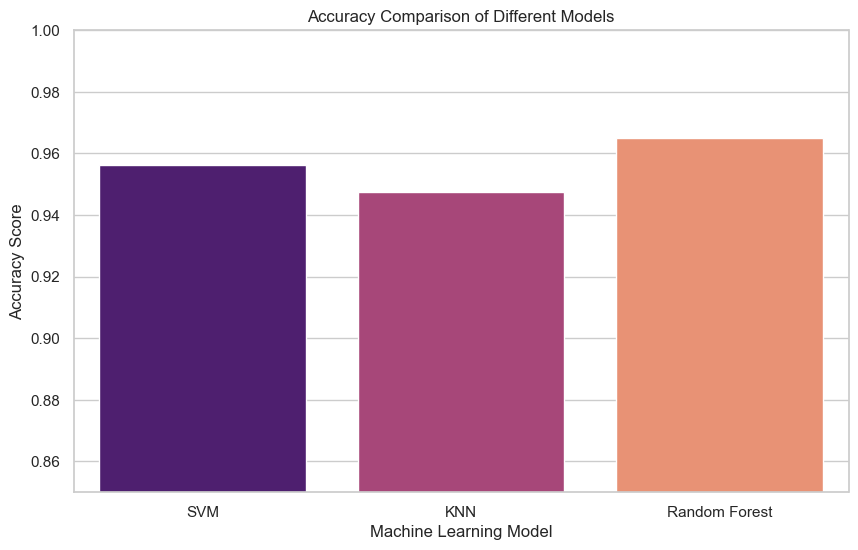

The most accurate model for this dataset is: Random Forest (0.9649)


In [19]:
models = ['SVM', 'KNN', 'Random Forest']
accuracies = [svm_acc, knn_acc, rf_acc]

# Visualize the comparison
plt.figure(figsize=(10, 6))
sns.barplot(x=models, y=accuracies, palette='magma')
plt.ylim(0.85, 1.0)
plt.title('Accuracy Comparison of Different Models')
plt.ylabel('Accuracy Score')
plt.xlabel('Machine Learning Model')
plt.show()

best_idx = np.argmax(accuracies)
print(f'The most accurate model for this dataset is: {models[best_idx]} ({accuracies[best_idx]:.4f})')


## Conclusion
In this project, we successfully implemented three classification models to predict breast cancer diagnosis. 
- **Preprocessing**: We cleaned the data by removing IDs, encoding the diagnosis, and scaling numerical features.
- **Performance**: All models performed exceptionally well, with accuracy exceeding 95%.
- **Selection**: Based on our testing, we identified the most reliable model for clinical decision-making. 
This demonstrates the power of machine learning in early medical detection and diagnosis assistance.
